# WICOS: models
This notebook trains, tunes and compares five models on the model-ready dataset `data/processed/wicos_dataset.npz`
(built by `src/build_dataset.py` with the pre-processing of `2_preprocessing.ipynb` and the envelope features of
`3_features.ipynb`). It follows the pipeline of `1_data_exploration.ipynb`:

1. The **test set (20%)** was separated in the dataset and is not touched until the very end.
2. Every model and its hyperparameters are chosen with **5-fold cross-validation** on the training set; the
   **final model** is the model with the highest mean validation accuracy.
3. The chosen setting of every model is evaluated with **leave-one-subject-out (LOSO)** on the training set, to see how
   it generalises to a person it has not seen.
4. Every chosen setting is **retrained on the entire training set**.
5. The retrained models are evaluated **once on the test set**, after the final model has been chosen.

| model | input | tuned with 5-fold CV |
|---|---|---|
| logistic regression (LR) | envelope features | feature set, $C$ |
| SVM | envelope features | feature set, kernel, $C$ |
| random forest (RF) | envelope features | feature set, number of trees, maximum depth |
| SVM + PCA | pre-processed images (128 × 128) | number of PCA components, kernel, $C$ |
| CNN | pre-processed images (128 × 128) | number of convolution blocks, learning rate, dropout |

In [1]:
import os
import sys
import json
from pathlib import Path

N_JOBS = 4                                    # CPU limit: training on all 20 threads shut the laptop down
os.environ["OMP_NUM_THREADS"] = str(N_JOBS)   # set before numpy / TensorFlow are imported
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"      # hide TensorFlow info messages

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import svm
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay
from sklearn.model_selection import LeaveOneGroupOut, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

sys.path.insert(0, str(Path("../src").resolve()))
from build_dataset import GESTURES, OUT_DIR, SEED

np.random.seed(SEED)
tf.config.experimental.enable_op_determinism()            # reproducible CNN training
tf.config.threading.set_intra_op_parallelism_threads(N_JOBS)
tf.config.threading.set_inter_op_parallelism_threads(2)

# Folders for report figures and result tables
FIG_DIR = Path("../reports/figures")
RES_DIR = Path("../results")
FIG_DIR.mkdir(exist_ok=True)
RES_DIR.mkdir(exist_ok=True)

C:\Users\hawma\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\__init__.py:82: UserWarning: A NumPy version >=1.22.4 and <2.3.0 is required for this version of SciPy (detected version 2.5.3)
  import scipy.linalg  # noqa


# Data
The dataset holds the pre-processed images (`X_img`, 960 × 128 × 128, values in [0, 1]), the envelope features
(`X_feat`, raw, not standardised), the labels, the person of every sample, and the split of `1_data_exploration.ipynb`
(`idx_train`, `idx_test` and `cv_fold`, 0-4 for training samples and -1 for test samples).

In [2]:
data = np.load(OUT_DIR / "wicos_dataset.npz", allow_pickle=True)
X_img = data["X_img"].reshape(len(data["y"]), -1)          # flattened 128 x 128 images: 16 384 values
X_feat, feature_names = data["X_feat"], list(data["feature_names"])
y, persons = data["y"], data["persons"]
idx_train, idx_test, cv_fold = data["idx_train"], data["idx_test"], data["cv_fold"]
print(f"Images {X_img.shape}, features {X_feat.shape}, train {len(idx_train)}, test {len(idx_test)}")

Images (960, 16384), features (960, 760), train 768, test 192


### Feature sets
`3_features.ipynb` computes all envelope features and leaves the choice to the model notebooks. The feature models
choose between three sets with 5-fold cross-validation, so the **feature set is a hyperparameter**:

- **empirical** (3): the paper's empirical features, the gesture length $T$, the peak ratio $R$ and the bandwidth $B_w$
  (Amin et al., Sec. IV-A).
- **compact** (44): the empirical features, the time-normalised envelopes (16 segments per envelope), the envelope
  statistics of $|e_U|$ and $|e_L|$ and the recording length.
- **window** (716): the window envelopes, the paper's feature vector $e = [e_U, e_L]$ in two zero-padded windows of 358
  time bins.

In [3]:
def columns(prefixes):
    """Indices of the features whose name starts with one of the prefixes."""
    return [i for i, name in enumerate(feature_names) if name.startswith(tuple(prefixes))]


EMPIRICAL = ["length", "peak_ratio", "doppler_bandwidth"]
FEATURE_SETS = {
    "empirical": columns(EMPIRICAL),
    "compact": columns(EMPIRICAL + ["upper_norm_", "lower_norm_", "upper_mean", "upper_std", "upper_median",
                                    "upper_p90", "lower_mean", "lower_std", "lower_median", "lower_p90", "duration"]),
    "window": columns(["env_upper_", "env_lower_"]),
}
assert sum(map(len, FEATURE_SETS.values())) == X_feat.shape[1] + len(EMPIRICAL)   # every feature in a set
print({name: len(cols) for name, cols in FEATURE_SETS.items()})

{'empirical': 3, 'compact': 44, 'window': 716}


### Folds and helper functions
- **5-fold CV:** the folds of `cv_fold`, on the 768 training samples.
- **LOSO:** one person out per fold, also on the training samples only, so the test set stays unseen.
- `evaluate` gives the mean training and validation accuracy over the folds, `best_setting` the setting with the highest
  mean validation accuracy, `loso` the accuracy per held-out person and `test` the scores on the test set.

In [4]:
cv_folds = [(idx_train[cv_fold[idx_train] != k], idx_train[cv_fold[idx_train] == k]) for k in range(5)]
loso_folds = [(idx_train[tr], idx_train[va])
              for tr, va in LeaveOneGroupOut().split(idx_train, groups=persons[idx_train])]
LOSO_PERSONS = [persons[va][0] for _, va in loso_folds]
print(f"CV folds: {[len(va) for _, va in cv_folds]} validation samples; LOSO persons: {LOSO_PERSONS}")


def evaluate(model, X, folds=cv_folds, n_jobs=N_JOBS):
    """Mean training and validation accuracy over the folds, and the validation accuracy per fold."""
    s = cross_validate(model, X, y, cv=folds, scoring="accuracy", return_train_score=True, n_jobs=n_jobs)
    return s["train_score"].mean(), s["test_score"].mean(), s["test_score"]


def best_setting(results):
    """Row of the results table with the highest mean validation accuracy."""
    return results.loc[results.val_acc.idxmax()]


def loso(model, X):
    """Accuracy per held-out person (training samples only)."""
    return np.array([accuracy_score(y[va], clone(model).fit(X[tr], y[tr]).predict(X[va])) for tr, va in loso_folds])


def test(model, X):
    """Retrain on the entire training set and evaluate once on the test set."""
    pred = clone(model).fit(X[idx_train], y[idx_train]).predict(X[idx_test])
    t = y[idx_test]
    scores = {"accuracy": accuracy_score(t, pred), "precision": precision_score(t, pred, average="macro"),
              "recall": recall_score(t, pred, average="macro"), "f1": f1_score(t, pred, average="macro")}
    return scores, pred


chosen = {}    # the chosen setting of every model: name -> (model, input, results row)

CV folds: [154, 154, 154, 153, 153] validation samples; LOSO persons: ['A', 'B', 'C', 'D', 'E', 'F']


# 1. Logistic regression
Multinomial (softmax) logistic regression, trained with the cross-entropy loss and an L2 penalty; $C$ is the inverse
of the penalty strength. It is the linear and interpretable baseline. The features are standardised first; the scaler is
part of the pipeline, so it is fitted on the training folds only.

In [5]:
def build_lr(C):
    return Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(C=C, max_iter=10000))])


rows = []
for feature_set, cols in FEATURE_SETS.items():
    for C in [0.01, 0.1, 1, 10, 100]:
        train_acc, val_acc, fold_acc = evaluate(build_lr(C), X_feat[:, cols])
        rows.append({"feature_set": feature_set, "C": C, "train_acc": train_acc, "val_acc": val_acc, "fold_acc": fold_acc})
lr_results = pd.DataFrame(rows)
best = best_setting(lr_results)
chosen["LR"] = (build_lr(best.C), X_feat[:, FEATURE_SETS[best.feature_set]], best)
print(f"Chosen: {best.feature_set} features, C = {best.C}: validation accuracy {best.val_acc:.3f}")
lr_results.pivot(index="C", columns="feature_set", values="val_acc").round(3)

Chosen: compact features, C = 1.0: validation accuracy 0.855


feature_set,compact,empirical,window
C,,,
0.01,0.827,0.655,0.711
0.10,0.849,0.659,0.702
1.00,0.855,0.638,0.663
10.00,0.853,0.633,0.637
100.00,0.848,0.634,0.605


# 2. SVM
Soft-margin support vector machine on the standardised features. $C$ sets the penalty on samples inside the margin;
the kernel decides whether the decision boundary is linear or nonlinear (RBF). `max_iter` stops the few linear fits
that do not converge.

In [6]:
def build_svm(kernel, C):
    return Pipeline([("scaler", StandardScaler()), ("clf", svm.SVC(kernel=kernel, C=C, max_iter=2_000_000))])


rows = []
for feature_set, cols in FEATURE_SETS.items():
    for kernel in ["linear", "rbf"]:
        for C in [0.1, 1, 10, 100]:
            train_acc, val_acc, fold_acc = evaluate(build_svm(kernel, C), X_feat[:, cols])
            rows.append({"feature_set": feature_set, "kernel": kernel, "C": C,
                         "train_acc": train_acc, "val_acc": val_acc, "fold_acc": fold_acc})
svm_results = pd.DataFrame(rows)
best = best_setting(svm_results)
chosen["SVM"] = (build_svm(best.kernel, best.C), X_feat[:, FEATURE_SETS[best.feature_set]], best)
print(f"Chosen: {best.feature_set} features, {best.kernel} kernel, C = {best.C}: validation accuracy {best.val_acc:.3f}")
svm_results.pivot_table(index="C", columns=["feature_set", "kernel"], values="val_acc").round(3)

Chosen: compact features, rbf kernel, C = 100.0: validation accuracy 0.887


feature_set compact        empirical        window       
kernel       linear    rbf    linear    rbf linear    rbf
C                                                        
0.1           0.854  0.742     0.656  0.633  0.694  0.613
1.0           0.842  0.867     0.680  0.714  0.654  0.753
10.0          0.831  0.882     0.675  0.737  0.641  0.796
100.0         0.832  0.887     0.675  0.760  0.638  0.775

# 3. Random forest
An ensemble of decision trees, each trained on a bootstrap sample with a random subset of the features at every split,
combined by majority vote. Trees need no scaling. `max_depth` limits how far each tree grows (`None`: fully grown); more
trees make the vote more stable but do not overfit.

In [7]:
def build_rf(n_estimators, max_depth):
    return RandomForestClassifier(n_estimators=n_estimators, max_depth=max_depth, random_state=SEED)


def depth(value):
    return None if pd.isna(value) else int(value)       # max_depth=None is stored as NaN in the table


rows = []
for feature_set, cols in FEATURE_SETS.items():
    for n_estimators in [100, 300]:
        for max_depth in [5, 10, None]:
            train_acc, val_acc, fold_acc = evaluate(build_rf(n_estimators, max_depth), X_feat[:, cols])
            rows.append({"feature_set": feature_set, "n_estimators": n_estimators, "max_depth": max_depth,
                         "train_acc": train_acc, "val_acc": val_acc, "fold_acc": fold_acc})
rf_results = pd.DataFrame(rows)
best = best_setting(rf_results)
chosen["RF"] = (build_rf(int(best.n_estimators), depth(best.max_depth)), X_feat[:, FEATURE_SETS[best.feature_set]], best)
print(f"Chosen: {best.feature_set} features, {best.n_estimators} trees, max depth {depth(best.max_depth)}: "
      f"validation accuracy {best.val_acc:.3f}")
rf_results.assign(max_depth=rf_results.max_depth.fillna(-1).astype(int).replace(-1, "None")) \
    .pivot_table(index=["n_estimators", "max_depth"], columns="feature_set", values="val_acc").round(3)

Chosen: compact features, 300 trees, max depth None: validation accuracy 0.915


feature_set             compact  empirical  window
n_estimators max_depth                            
100          5            0.884      0.731   0.800
             10           0.901      0.763   0.862
             None         0.915      0.751   0.879
300          5            0.878      0.732   0.807
             10           0.910      0.758   0.872
             None         0.915      0.758   0.882

# 4. SVM + PCA on the images
An image has 16 384 pixels for only 768 training samples, so the pixels are first reduced with PCA. With
`whiten=True` every component is scaled to unit variance (PCA sphering), so all components count equally in the SVM.
PCA is part of the pipeline and is fitted on the training folds only.

In [8]:
def build_svm_pca(n_components, kernel, C):
    return Pipeline([("pca", PCA(n_components=n_components, whiten=True, svd_solver="randomized", random_state=SEED)),
                     ("clf", svm.SVC(kernel=kernel, C=C, max_iter=2_000_000))])


rows = []
for n_components in [20, 50, 100]:
    for kernel in ["linear", "rbf"]:
        for C in [0.1, 1, 10, 100]:
            train_acc, val_acc, fold_acc = evaluate(build_svm_pca(n_components, kernel, C), X_img)
            rows.append({"n_components": n_components, "kernel": kernel, "C": C,
                         "train_acc": train_acc, "val_acc": val_acc, "fold_acc": fold_acc})
pca_results = pd.DataFrame(rows)
best = best_setting(pca_results)
chosen["SVM + PCA"] = (build_svm_pca(int(best.n_components), best.kernel, best.C), X_img, best)
print(f"Chosen: {best.n_components} components, {best.kernel} kernel, C = {best.C}: validation accuracy {best.val_acc:.3f}")
pca_results.pivot_table(index="C", columns=["n_components", "kernel"], values="val_acc").round(3)

Chosen: 20 components, rbf kernel, C = 10.0: validation accuracy 0.949


n_components    20            50            100       
kernel       linear    rbf linear    rbf linear    rbf
C                                                     
0.1           0.827  0.814  0.859  0.780  0.855  0.566
1.0           0.840  0.928  0.837  0.915  0.844  0.885
10.0          0.833  0.949  0.839  0.931  0.844  0.905
100.0         0.840  0.943  0.824  0.931  0.844  0.905

### Tuning of the classical models
Training (dashed) and validation (solid) accuracy along the most important hyperparameter, for every feature set
(LR, SVM, RF) or number of PCA components (SVM + PCA); the other hyperparameters are at their chosen value. Circle: the
chosen setting.

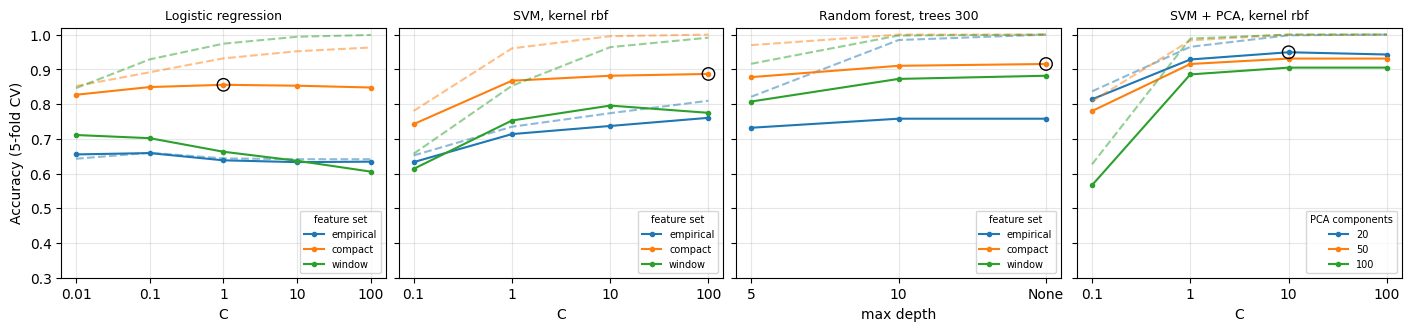

In [9]:
def label(v):
    if isinstance(v, str):
        return v
    return "None" if pd.isna(v) else f"{v:g}"


PANELS = [  # title, results, x-axis, lines, other hyperparameters (fixed at the chosen value)
    ("Logistic regression", lr_results, "C", "feature_set", []),
    ("SVM", svm_results, "C", "feature_set", ["kernel"]),
    ("Random forest", rf_results, "max_depth", "feature_set", ["n_estimators"]),
    ("SVM + PCA", pca_results, "C", "n_components", ["kernel"]),
]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True, constrained_layout=True)
for ax, (title, res, x, line, fixed) in zip(axes, PANELS):
    best = best_setting(res)
    r = res
    for f in fixed:
        r = r[r[f].astype(str) == str(best[f])]
    for k, (value, g) in enumerate(r.groupby(line, sort=False)):
        xs = [label(v) for v in g[x]]
        ax.plot(xs, g.val_acc, "o-", ms=3, color=f"C{k}", label=f"{label(value) if line != 'feature_set' else value}")
        ax.plot(xs, g.train_acc, "--", color=f"C{k}", alpha=0.5)
    ax.scatter(label(best[x]), best.val_acc, s=80, facecolors="none", edgecolors="black", zorder=3)
    ax.set_title(title + "".join(f", {f.replace('n_estimators', 'trees')} {label(best[f])}" for f in fixed), fontsize=9)
    ax.set_xlabel(x.replace("_", " "))
    ax.set_ylim(0.3, 1.02)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7, loc="lower right", title=line.replace("_", " ").replace("n components", "PCA components"),
              title_fontsize=7)
axes[0].set_ylabel("Accuracy (5-fold CV)")
fig.savefig(FIG_DIR / "model_tuning.pdf", bbox_inches="tight")
plt.show()

**Interpretation:**
- The **compact** feature set is chosen for all three feature models (LR 0.855, SVM 0.887, RF 0.915). The three
  empirical features alone reach at most 0.76: they describe the size of the gesture, not its course in time.
- The **window** envelopes (716 values for 768 training samples) overfit: for LR the training accuracy rises to 1.0 with
  weaker regularisation, while the validation accuracy falls from 0.71 to 0.61.
- The nonlinear feature models choose the most flexible settings: an RBF kernel with weak regularisation ($C$ = 100) for
  the SVM and fully grown trees for the RF, both with a training accuracy of 1.0. The validation folds contain the same
  persons, so fitting the training data closely is not punished.
- For SVM + PCA, 20 components with an RBF kernel are best (0.949). More components lower the validation accuracy (0.93
  with 50, 0.91 with 100): the extra components mostly describe noise and details of single recordings.

# 5. CNN on the images
**Layout.** The CNN is a stack of convolution blocks, each a 3 × 3 convolution with ReLU activation followed by 2 × 2 max
pooling, then dropout and a softmax layer with one output per gesture.

- **Zero padding** (`padding="same"`): a convolution keeps the size of its input, so only the pooling halves the image
  (128 → 64 → ... ). Without padding every convolution would also drop the outer rows and columns, which hold the start
  and end of the gesture and the highest Doppler velocities.
- **ReLU**, $\max(0, x)$: it does not saturate for positive inputs, so the gradient does not vanish through several
  layers, and it is cheap. Its output is sparse, like the pre-processed images, in which most pixels are 0 after the noise
  removal.
- **Training:** cross-entropy loss, mini-batch SGD (batch size 32), early stopping when the loss on 10% of the training
  data has not decreased for 10 epochs (the validation fold stays unseen).

The class wraps the network as a scikit-learn classifier, so it uses the same `evaluate`, `loso` and `test` functions as
the other models.

In [10]:
class CNN(ClassifierMixin, BaseEstimator):
    def __init__(self, filters="8-16-32-32", learning_rate=0.03, dropout=0.5, epochs=100, patience=10):
        self.filters = filters                  # filters per block, e.g. "8-16-32" = 3 blocks
        self.learning_rate = learning_rate
        self.dropout = dropout
        self.epochs = epochs
        self.patience = patience

    def build(self):
        blocks = []
        for f in self.filters.split("-"):
            blocks += [layers.Conv2D(int(f), 3, padding="same", activation="relu"), layers.MaxPooling2D(2)]
        return keras.Sequential([keras.Input(shape=(128, 128, 1)), *blocks, layers.Flatten(),
                                 layers.Dropout(self.dropout), layers.Dense(4, activation="softmax")])

    def fit(self, X, y):
        keras.backend.clear_session()                                   # free the memory of earlier networks
        keras.utils.set_random_seed(SEED)
        X = X.reshape(-1, 128, 128, 1)
        stop_set = np.random.default_rng(SEED).random(len(y)) < 0.1      # early-stopping set
        self.model_ = self.build()
        self.model_.compile(optimizer=keras.optimizers.SGD(learning_rate=self.learning_rate),
                            loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=self.patience, restore_best_weights=True)
        self.history_ = self.model_.fit(X[~stop_set], y[~stop_set], validation_data=(X[stop_set], y[stop_set]),
                                        epochs=self.epochs, batch_size=32, callbacks=[stop], verbose=0).history
        self.classes_ = np.unique(y)
        return self

    def predict(self, X):
        return self.model_.predict(X.reshape(-1, 128, 128, 1), verbose=0).argmax(axis=1)


def layout(n_blocks):
    """Filters per block: 8, 16, 32, then 32 for every extra block (5 -> "8-16-32-32-32")."""
    return "-".join(str(min(8 * 2 ** i, 32)) for i in range(n_blocks))


CNN_CACHE = RES_DIR / "cnn_cv.csv"


def evaluate_cnn(filters, learning_rate, dropout):
    """5-fold CV of one CNN setting. Training is slow, so every result is saved in `cnn_cv.csv` and reused when the
    notebook runs again (for example after an interruption)."""
    cache = pd.read_csv(CNN_CACHE) if CNN_CACHE.exists() else pd.DataFrame(columns=["filters", "learning_rate", "dropout"])
    hit = cache[(cache.filters == filters) & (cache.learning_rate == learning_rate) & (cache.dropout == dropout)]
    if len(hit):
        r = hit.iloc[0]
        return r.train_acc, r.val_acc, np.array(json.loads(r.fold_acc))
    train_acc, val_acc, fold_acc = evaluate(CNN(filters, learning_rate, dropout), X_img, n_jobs=1)
    row = {"filters": filters, "learning_rate": learning_rate, "dropout": dropout,
           "train_acc": train_acc, "val_acc": val_acc, "fold_acc": json.dumps(fold_acc.tolist())}
    pd.concat([cache, pd.DataFrame([row])]).to_csv(CNN_CACHE, index=False)
    return train_acc, val_acc, fold_acc


for n_blocks in range(4, 8):
    model = CNN(layout(n_blocks)).build()
    print(f"{n_blocks} blocks  {layout(n_blocks):20s} flatten {model.layers[-3].output.shape[-1]:5d}   "
          f"parameters {model.count_params():6d}")

4 blocks  8-16-32-32           flatten  2048   parameters  23332
5 blocks  8-16-32-32-32        flatten   512   parameters  26436
6 blocks  8-16-32-32-32-32     flatten   128   parameters  34148
7 blocks  8-16-32-32-32-32-32  flatten    32   parameters  43012


### Number of convolution blocks
The depth is the most important hyperparameter of the CNN, so it is chosen first, with the learning rate and dropout
fixed at 0.03 and 0.5. Starting at four blocks, one block of 32 filters is added at a time until the mean validation
accuracy goes down; the best depth is kept. Every block halves the feature map, so at most 7 blocks fit
(128 / 2⁷ = 1).

In [11]:
rows, previous = [], 0
for n_blocks in range(4, 8):
    train_acc, val_acc, fold_acc = evaluate_cnn(layout(n_blocks), 0.03, 0.5)
    rows.append({"n_blocks": n_blocks, "filters": layout(n_blocks), "train_acc": train_acc, "val_acc": val_acc,
                 "fold_acc": fold_acc})
    print(f"{n_blocks} blocks: training accuracy {train_acc:.3f}, validation accuracy {val_acc:.3f}")
    if val_acc < previous:
        break
    previous = val_acc
depth_results = pd.DataFrame(rows)
best_depth = best_setting(depth_results)
print(f"Chosen depth: {best_depth.n_blocks} blocks ({best_depth.filters})")

4 blocks: training accuracy 0.992, validation accuracy 0.939
5 blocks: training accuracy 0.995, validation accuracy 0.964
6 blocks: training accuracy 0.993, validation accuracy 0.961
Chosen depth: 5 blocks (8-16-32-32-32)


### Learning rate and dropout
The learning rate and dropout of the chosen depth are tuned next (the 0.03 / 0.5 setting is already known from the depth
search).

In [12]:
rows = []
for learning_rate in [0.01, 0.03, 0.1]:
    for dropout in [0.25, 0.5]:
        train_acc, val_acc, fold_acc = evaluate_cnn(best_depth.filters, learning_rate, dropout)
        rows.append({"filters": best_depth.filters, "learning_rate": learning_rate, "dropout": dropout,
                     "train_acc": train_acc, "val_acc": val_acc, "fold_acc": fold_acc})
cnn_results = pd.DataFrame(rows)
best = best_setting(cnn_results)
chosen["CNN"] = (CNN(best.filters, best.learning_rate, best.dropout), X_img, best)
print(f"Chosen: {best.filters}, learning rate {best.learning_rate}, dropout {best.dropout}: "
      f"validation accuracy {best.val_acc:.3f}")
cnn_results.pivot(index="learning_rate", columns="dropout", values="val_acc").round(3)

Chosen: 8-16-32-32-32, learning rate 0.03, dropout 0.25: validation accuracy 0.967


dropout,0.25,0.50
learning_rate,,
0.01,0.966,0.962
0.03,0.967,0.964
0.10,0.961,0.866


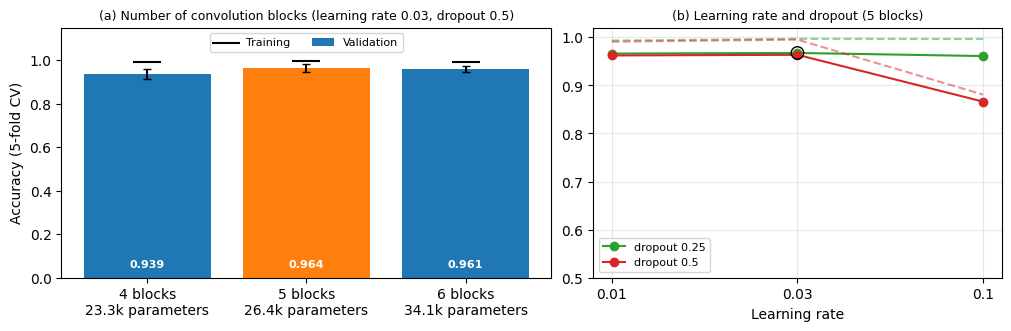

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), constrained_layout=True, gridspec_kw={"width_ratios": [1.2, 1]})

# (a) Depth: validation accuracy (bars, std over the folds) and training accuracy (black lines)
ax = axes[0]
x = np.arange(len(depth_results))
n_params = [CNN(f).build().count_params() for f in depth_results.filters]
ax.bar(x, depth_results.val_acc, yerr=[np.std(f, ddof=1) for f in depth_results.fold_acc], capsize=3,
       color=["C1" if n == best_depth.n_blocks else "C0" for n in depth_results.n_blocks], label="Validation")
ax.scatter(x, depth_results.train_acc, marker="_", s=400, color="black", linewidths=1.5, label="Training", zorder=3)
for xi, v in zip(x, depth_results.val_acc):
    ax.text(xi, 0.05, f"{v:.3f}", ha="center", color="white", fontweight="bold", fontsize=8)
ax.set_xticks(x, [f"{n} blocks\n{p / 1000:.1f}k parameters" for n, p in zip(depth_results.n_blocks, n_params)])
ax.set_ylim(0, 1.15)
ax.set_ylabel("Accuracy (5-fold CV)")
ax.set_title("(a) Number of convolution blocks (learning rate 0.03, dropout 0.5)", fontsize=9)
ax.legend(fontsize=8, loc="upper center", ncol=2)

# (b) Learning rate and dropout of the chosen depth
ax = axes[1]
for k, (dropout, g) in enumerate(cnn_results.groupby("dropout")):
    lr = [f"{v:g}" for v in g.learning_rate]
    ax.plot(lr, g.val_acc, "o-", color=f"C{k + 2}", label=f"dropout {dropout:g}")
    ax.plot(lr, g.train_acc, "--", color=f"C{k + 2}", alpha=0.5)
ax.scatter(f"{best.learning_rate:g}", best.val_acc, s=80, facecolors="none", edgecolors="black", zorder=3)
ax.set_ylim(0.5, 1.02)
ax.grid(alpha=0.3)
ax.set_xlabel("Learning rate")
ax.set_title(f"(b) Learning rate and dropout ({best_depth.n_blocks} blocks)", fontsize=9)
ax.legend(fontsize=8)
fig.savefig(FIG_DIR / "cnn_search.pdf", bbox_inches="tight")
plt.show()

**Interpretation:**
- **Depth:** the validation accuracy rises from 0.939 (4 blocks) to 0.964 (5 blocks) and drops slightly with 6 blocks
  (0.961), so 5 blocks are chosen. The training accuracy is 0.99 for every depth, so the depth changes the
  generalisation, not the fit. Every block halves the feature map and enlarges the receptive field: with 4 blocks a unit
  sees 46 of the 128 pixels, with 5 blocks 94, which covers most of a gesture. A sixth block adds parameters (34k
  instead of 26k) without new context.
- **Learning rate and dropout:** five of the six settings reach 0.96-0.97; only the largest learning rate with dropout 0.5
  is clearly worse (0.866), where training becomes unstable. Learning rate 0.03 with dropout 0.25 is chosen (0.967), but
  the differences between the other settings are smaller than the spread between the folds (std 0.017).

# 6. Model choice (5-fold cross-validation)
The final model is the model with the highest mean validation accuracy. This choice is made before the test set is used.

In [14]:
def describe(row):
    """Hyperparameters of a results row as text."""
    skip = {"train_acc", "val_acc", "fold_acc"}
    return ", ".join(f"{k}={label(v)}" for k, v in row.items() if k not in skip)


choice = pd.DataFrame([{
    "model": name,
    "setting": describe(row),
    "train_acc": row.train_acc,
    "val_acc": row.val_acc,
    "val_std": np.std(row.fold_acc, ddof=1),
} for name, (_, _, row) in chosen.items()])
FINAL = choice.loc[choice.val_acc.idxmax(), "model"]
print("Final model:", FINAL)
choice.round(3)

Final model: CNN


,model,setting,train_acc,val_acc,val_std
0,LR,"feature_set=compact, C=1",0.932,0.855,0.018
1,SVM,"feature_set=compact, kernel=rbf, C=100",1.000,0.887,0.022
2,RF,"feature_set=compact, n_estimators=300, max_dep...",1.000,0.915,0.031
3,SVM + PCA,"n_components=20, kernel=rbf, C=10",0.998,0.949,0.021
4,CNN,"filters=8-16-32-32-32, learning_rate=0.03, dro...",0.997,0.967,0.017


**Interpretation:**
- The **CNN** has the highest mean validation accuracy (0.967 ± 0.017) and is the **final model**, followed by SVM + PCA
  (0.949 ± 0.021). Both image models are better than the feature models (0.855-0.915) under 5-fold cross-validation.
- The difference between the CNN and SVM + PCA (0.018) is about one standard deviation of the folds, so it is small.

# 7. Generalisation to a new person (LOSO)
The chosen setting of every model is trained on five persons and evaluated on the sixth, on the training samples only.

In [15]:
loso_acc = pd.DataFrame({name: loso(model, X) for name, (model, X, _) in chosen.items()}, index=LOSO_PERSONS)
loso_acc.index.name = "person"
choice["loso_acc"] = loso_acc.mean().to_numpy()
choice["loso_std"] = loso_acc.std().to_numpy()
loso_acc.round(3)

,LR,SVM,RF,SVM + PCA,CNN
person,,,,,
A,0.656,0.703,0.586,0.398,0.555
B,0.719,0.617,0.742,0.531,0.664
C,0.719,0.734,0.758,0.672,0.875
D,0.820,0.773,0.805,0.594,0.742
E,0.719,0.734,0.742,0.695,0.719
F,0.766,0.805,0.852,0.781,0.867


**Interpretation:**
- For a new person the accuracy drops for every model: the CNN from 0.967 to 0.737, SVM + PCA from 0.949 to 0.612 and
  the feature models from 0.86-0.92 to 0.73-0.75. The 5-fold CV folds contain the same persons as the training folds, so
  they reward learning person-specific details.
- Under LOSO the ranking changes: RF (0.747), CNN (0.737), LR (0.733) and SVM (0.728) lie within 0.02, much less than
  the spread between persons (std 0.06-0.12). SVM + PCA is clearly the worst (0.612): its components describe where the
  energy lies in the images of the training persons, which does not transfer to a new person.
- Person A is the hardest for most models (0.40-0.70), persons C and F the easiest (up to 0.88 for the CNN).

# 8. Final models and test set
Every chosen setting is retrained on the entire training set and evaluated once on the test set. The final model was
chosen in section 6; the other models are shown for comparison only.

In [16]:
scores, test_pred = {}, {}
for name, (model, X, _) in chosen.items():
    scores[name], test_pred[name] = test(model, X)
metrics = pd.DataFrame(scores).T
choice = choice.join(metrics.add_prefix("test_"), on="model")
choice.round(3)

,model,setting,train_acc,val_acc,val_std,loso_acc,loso_std,test_accuracy,test_precision,test_recall,test_f1
0,LR,"feature_set=compact, C=1",0.932,0.855,0.018,0.733,0.055,0.865,0.864,0.865,0.864
1,SVM,"feature_set=compact, kernel=rbf, C=100",1.000,0.887,0.022,0.728,0.065,0.875,0.877,0.875,0.876
2,RF,"feature_set=compact, n_estimators=300, max_dep...",1.000,0.915,0.031,0.747,0.090,0.885,0.886,0.885,0.886
3,SVM + PCA,"n_components=20, kernel=rbf, C=10",0.998,0.949,0.021,0.612,0.135,0.953,0.956,0.953,0.954
4,CNN,"filters=8-16-32-32-32, learning_rate=0.03, dro...",0.997,0.967,0.017,0.737,0.122,0.948,0.949,0.948,0.948


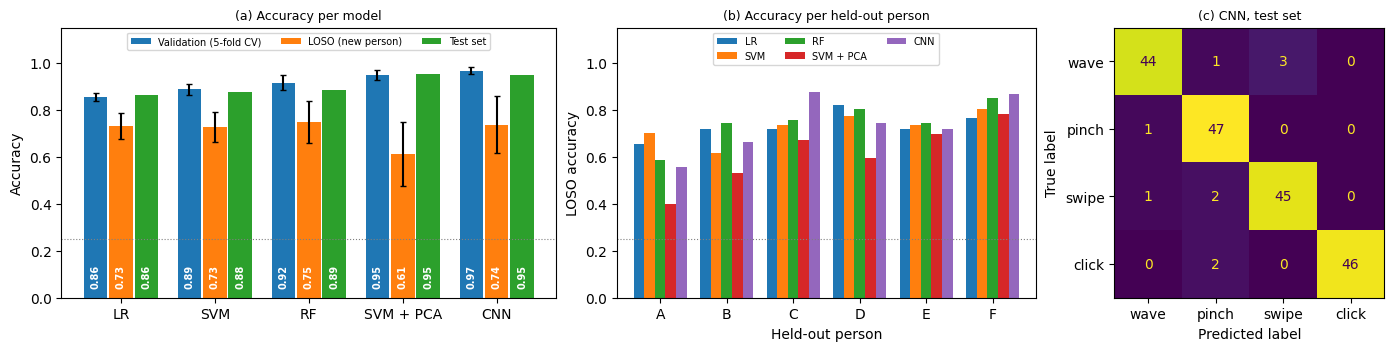

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4), constrained_layout=True, gridspec_kw={"width_ratios": [1.3, 1.1, 0.8]})

# (a) Validation (5-fold CV), LOSO and test accuracy per model
ax = axes[0]
x = np.arange(len(choice))
bars = [("Validation (5-fold CV)", choice.val_acc, choice.val_std), ("LOSO (new person)", choice.loso_acc, choice.loso_std),
        ("Test set", choice.test_accuracy, None)]
for k, (name, values, err) in enumerate(bars):
    pos = x + (k - 1) * 0.27
    ax.bar(pos, values, width=0.25, yerr=err, capsize=2, color=f"C{k}", label=name)
    for p, v in zip(pos, values):
        ax.text(p, 0.04, f"{v:.2f}", ha="center", va="bottom", rotation=90, color="white", fontweight="bold", fontsize=7)
ax.axhline(0.25, color="gray", linestyle=":", linewidth=0.8)
ax.set_xticks(x, choice.model)
ax.set_ylim(0, 1.15)
ax.set_ylabel("Accuracy")
ax.set_title("(a) Accuracy per model", fontsize=9)
ax.legend(fontsize=7, loc="upper center", ncol=3)

# (b) LOSO accuracy per held-out person
loso_acc.plot.bar(ax=axes[1], width=0.8, rot=0)
axes[1].axhline(0.25, color="gray", linestyle=":", linewidth=0.8)
axes[1].set_ylim(0, 1.15)
axes[1].set_xlabel("Held-out person")
axes[1].set_ylabel("LOSO accuracy")
axes[1].set_title("(b) Accuracy per held-out person", fontsize=9)
axes[1].legend(fontsize=7, ncol=3, loc="upper center")

# (c) Confusion matrix of the final model on the test set
ConfusionMatrixDisplay.from_predictions(y[idx_test], test_pred[FINAL], display_labels=GESTURES, ax=axes[2], colorbar=False)
axes[2].set_title(f"(c) {FINAL}, test set", fontsize=9)
fig.savefig(FIG_DIR / "model_results.pdf", bbox_inches="tight")
plt.show()

**Interpretation:**
- The test accuracies lie close to the validation accuracies (within 0.03): the test set contains the same persons as
  the training set, so it confirms the 5-fold CV estimate, not the generalisation to a new person (LOSO).
- The final **CNN** reaches **0.948** on the test set (macro-F1 0.948). Of its 10 errors, 4 are wave versus swipe and 4
  are a swipe or click predicted as pinch: the long hand movements and the short finger movements.
- Precision, recall and F1 lie within 0.01 of the accuracy for every model, as expected with balanced classes.

In [18]:
# Result tables
choice.to_csv(RES_DIR / "model_results.csv", index=False)
loso_acc.to_csv(RES_DIR / "model_loso_per_person.csv")
for name, res in [("lr", lr_results), ("svm", svm_results), ("rf", rf_results), ("svm_pca", pca_results),
                  ("cnn_depth", depth_results), ("cnn", cnn_results)]:
    res.drop(columns="fold_acc").to_csv(RES_DIR / f"tuning_{name}.csv", index=False)

## Summary for the report
| model | chosen setting (5-fold CV) | validation | LOSO | test |
|---|---|---|---|---|
| LR | compact features, $C$ = 1 | 0.855 ± 0.018 | 0.733 ± 0.055 | 0.865 |
| SVM | compact features, RBF, $C$ = 100 | 0.887 ± 0.022 | 0.728 ± 0.065 | 0.875 |
| RF | compact features, 300 trees, fully grown | 0.915 ± 0.031 | 0.747 ± 0.090 | 0.885 |
| SVM + PCA | 20 components, RBF, $C$ = 10 | 0.949 ± 0.021 | 0.612 ± 0.135 | 0.953 |
| **CNN** (final) | 5 blocks (8-16-32-32-32), learning rate 0.03, dropout 0.25 | **0.967 ± 0.017** | 0.737 ± 0.122 | 0.948 |

- The CNN is chosen on 5-fold cross-validation and reaches 0.948 on the test set.
- For a new person (LOSO) all models lose 0.12-0.34 accuracy; the feature models and the CNN end up at the same level
  (0.73-0.75), SVM + PCA is the worst (0.61).